# Bài tập 2 — Từ nào tố cáo mạnh nhất
Huấn luyện MultinomialNB trên toàn bộ 300 tin, xếp theo hiệu log xác suất giữa lớp rác và lớp thường.

Chọn **Run All** để chạy độc lập notebook này. Trên Colab, tải CSV cần dùng vào Files hoặc thư mục `data/`.


In [1]:
from pathlib import Path

# Chạy từ thư mục bài, code/, hoặc thư mục chứa CSV đã tải lên Colab.
thu_muc_hien_tai = Path.cwd().resolve()
thu_muc_du_an = thu_muc_hien_tai
for thu_muc in (thu_muc_hien_tai, *thu_muc_hien_tai.parents):
    if (thu_muc / "data" / "tin_nhan.csv").is_file():
        thu_muc_du_an = thu_muc
        break

def tep_du_lieu(ten):
    for duong_dan in (thu_muc_du_an / "data" / ten, thu_muc_hien_tai / ten):
        if duong_dan.is_file():
            return duong_dan
    raise FileNotFoundError(f"Không tìm thấy {ten}. Hãy giữ thư mục data/ hoặc tải CSV lên Colab.")

thu_muc_hinh = thu_muc_du_an / "figures"
thu_muc_hinh.mkdir(exist_ok=True)


## Mã và kết quả

In [2]:
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB

df = pd.read_csv(tep_du_lieu("tin_nhan.csv"))
vec = CountVectorizer(token_pattern=r"(?u)\S+")
X = vec.fit_transform(df["noi_dung"])
mo_hinh = MultinomialNB(alpha=1.0).fit(X, df["la_rac"])
# classes_ là [0, 1]: lấy log P(từ|rác) trừ log P(từ|thường).
chenh_lech = mo_hinh.feature_log_prob_[1] - mo_hinh.feature_log_prob_[0]
bang = pd.DataFrame({"tu": vec.get_feature_names_out(), "chenh_lech_log": chenh_lech})
tu_rac = bang.sort_values("chenh_lech_log", ascending=False).head(5)
tu_thuong = bang.sort_values("chenh_lech_log").head(5)
print("5 từ tố cáo tin rác mạnh nhất:")
print(tu_rac.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("\n5 từ cho thấy tin thường mạnh nhất:")
print(tu_thuong.to_string(index=False, float_format=lambda x: f"{x:.6f}"))
print("Nhận xét: Hiệu log dương nghiêng về tin rác; hiệu log âm nghiêng về tin thường. Độ lớn cho biết mức chênh lệch xác suất của từ giữa hai lớp.")

5 từ tố cáo tin rác mạnh nhất:
   tu  chenh_lech_log
  mãi        3.203435
  tay        2.905600
 ngay        2.661837
 miễn        2.479516
trúng        2.374155

5 từ cho thấy tin thường mạnh nhất:
   tu  chenh_lech_log
  lớp       -2.612187
   em       -2.561756
  bài       -2.294553
  báo       -2.274074
phòng       -2.274074
Nhận xét: Hiệu log dương nghiêng về tin rác; hiệu log âm nghiêng về tin thường. Độ lớn cho biết mức chênh lệch xác suất của từ giữa hai lớp.


## Hình minh họa bổ sung
Phần vẽ dưới đây bổ sung cho mã mẫu; hình được lưu vào `figures/` trước khi hiển thị.

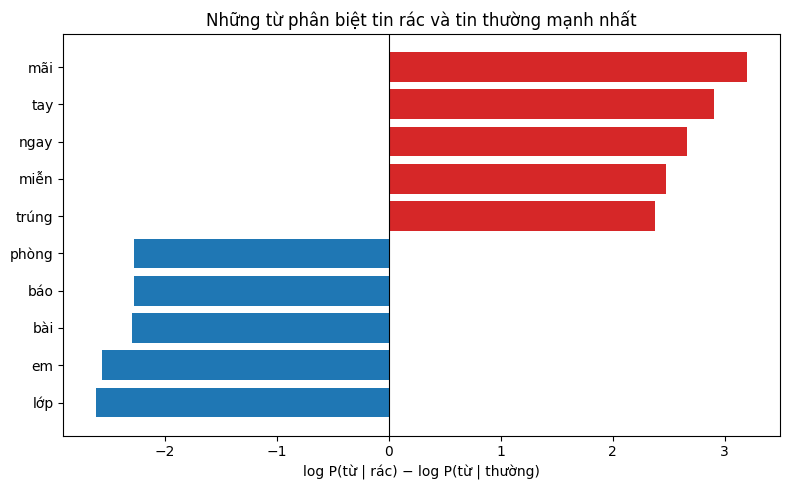

In [3]:
import matplotlib.pyplot as plt

ve = pd.concat([tu_thuong, tu_rac]).sort_values("chenh_lech_log")
plt.figure(figsize=(8, 5))
plt.barh(ve.tu, ve.chenh_lech_log, color=["tab:red" if v > 0 else "tab:blue" for v in ve.chenh_lech_log])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Những từ phân biệt tin rác và tin thường mạnh nhất")
plt.xlabel("log P(từ | rác) − log P(từ | thường)")
plt.tight_layout()
plt.savefig(thu_muc_hinh / "bai2_tu_to_cao.png", dpi=150)
plt.show()